<a href="https://colab.research.google.com/github/HusnulAmira/ADW/blob/main/BCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumlah observasi: 5505
Data paling awal: 2004-06-08 00:00:00
Data paling baru: 2026-10-09 00:00:00

Lima data pertama:
Price       Adj Close  Close   High    Low   Open     Volume
Date                                                        
2004-06-08  94.219917  177.5  180.0  175.0  175.0  499150000
2004-06-09  95.546974  180.0  182.5  175.0  177.5  294290000
2004-06-10  95.546974  180.0  180.0  177.5  180.0  165590000
2004-06-11  95.546974  180.0  180.0  177.5  177.5  135830000
2004-06-14  94.219917  177.5  180.0  175.0  180.0  158540000

Informasi data:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5505 entries, 2004-06-08 to 2026-10-09
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  5505 non-null   float64
 1   Close      5505 non-null   float64
 2   High       5505 non-null   float64
 3   Low        5505 non-null   float64
 4   Open       5505 non-null   float64
 5   Volume     5505 non-null   i

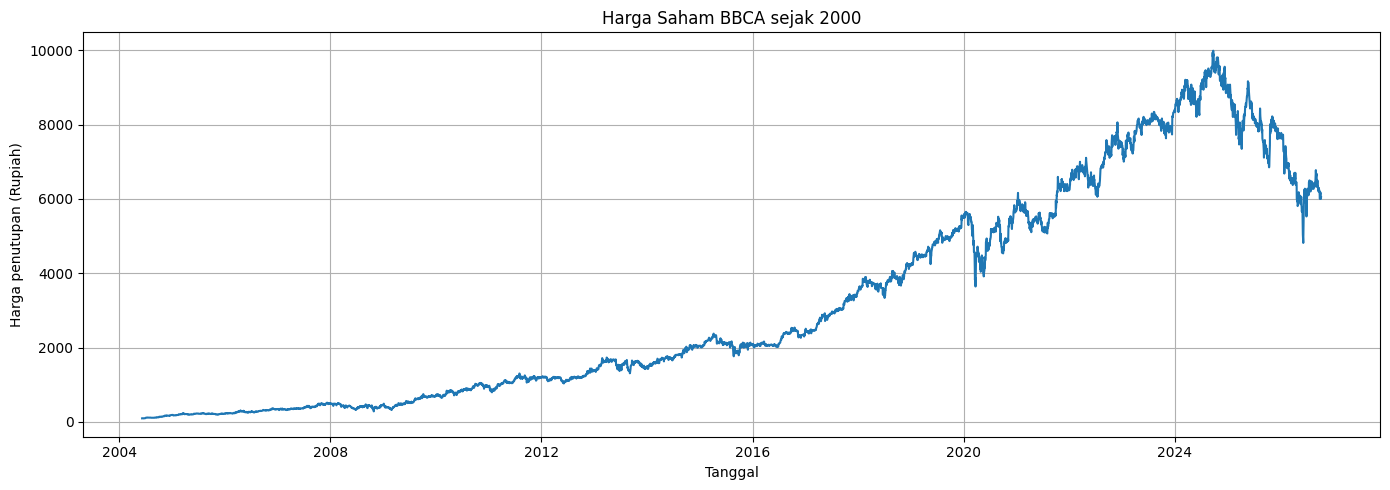


Statistik deskriptif:
count    5505.000000
mean     3181.845010
std      2835.473087
min        94.219917
25%       688.245422
50%      2062.562500
75%      5436.685059
max      9989.795898
Name: BBCA, dtype: float64


In [ ]:

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Mengunduh data historis BBCA sejak IPO
df = yf.download(
    "BBCA.JK",
    start="2000-05-31",
    auto_adjust=False,
    progress=False
)

# 2. Mengatasi format kolom MultiIndex dari yfinance
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Memeriksa ketersediaan data
print("Jumlah observasi:", len(df))
print("Data paling awal:", df.index.min())
print("Data paling baru:", df.index.max())
print("\nLima data pertama:")
print(df.head())

print("\nInformasi data:")
print(df.info())

print("\nJumlah missing value:")
print(df.isnull().sum())

# 4. Memilih harga penutupan yang sudah disesuaikan
# Jika Adj Close tidak tersedia, gunakan Close
kolom_harga = "Adj Close" if "Adj Close" in df.columns else "Close"
harga = df[kolom_harga].dropna().astype(float)
harga.name = "BBCA"

# 5. Plot harga saham
plt.figure(figsize=(14, 5))
plt.plot(harga)
plt.title("Harga Saham BBCA sejak 2000")
plt.xlabel("Tanggal")
plt.ylabel("Harga penutupan (Rupiah)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Statistik deskriptif
print("\nStatistik deskriptif:")
print(harga.describe())


In [ ]:

# ============================================================
# TAHAP 1A. IMPORT LIBRARY DAN DOWNLOAD DATA BBCA
# ============================================================

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mengunduh data historis BBCA sejak 31 Mei 2000
df = yf.download(
    "BBCA.JK",
    start="2000-05-31",
    auto_adjust=False,
    progress=False
)

# Mengatasi kolom MultiIndex pada yfinance versi terbaru
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Memastikan data berhasil diunduh
if df.empty:
    raise ValueError(
        "Data kosong. Periksa koneksi internet atau ticker BBCA.JK."
    )

# Mengurutkan data berdasarkan tanggal
df = df.sort_index()

# Memeriksa data
print("=" * 60)
print("INFORMASI DATA SAHAM BBCA")
print("=" * 60)

print("Jumlah observasi :", len(df))
print("Tanggal awal     :", df.index.min())
print("Tanggal akhir    :", df.index.max())
print("Jumlah variabel  :", len(df.columns))

print("\nNama variabel:")
print(df.columns.tolist())

print("\nLima observasi pertama:")
print(df.head())

print("\nLima observasi terakhir:")
print(df.tail())

print("\nInformasi struktur data:")
df.info()


INFORMASI DATA SAHAM BBCA
Jumlah observasi : 5505
Tanggal awal     : 2004-06-08 00:00:00
Tanggal akhir    : 2026-10-09 00:00:00
Jumlah variabel  : 6

Nama variabel:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']

Lima observasi pertama:
Price       Adj Close  Close   High    Low   Open     Volume
Date                                                        
2004-06-08  94.219940  177.5  180.0  175.0  175.0  499150000
2004-06-09  95.546928  180.0  182.5  175.0  177.5  294290000
2004-06-10  95.546928  180.0  180.0  177.5  180.0  165590000
2004-06-11  95.546928  180.0  180.0  177.5  177.5  135830000
2004-06-14  94.219940  177.5  180.0  175.0  180.0  158540000

Lima observasi terakhir:
Price       Adj Close   Close    High     Low    Open     Volume
Date                                                            
2026-10-05     6175.0  6175.0  6175.0  6075.0  6100.0   89895500
2026-10-06     6100.0  6100.0  6200.0  6100.0  6175.0  152173400
2026-10-07     6050.0  6050.0  6100.0  59

In [ ]:

# ============================================================
# TAHAP 1B. PEMERIKSAAN MISSING VALUE
# ============================================================

print("JUMLAH MISSING VALUE")
print(df.isnull().sum())

print("\nPERSENTASE MISSING VALUE (%)")
print((df.isnull().mean() * 100).round(2))

# Statistik deskriptif
print("\nSTATISTIK DESKRIPTIF")
print(df.describe().round(2))


JUMLAH MISSING VALUE
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

PERSENTASE MISSING VALUE (%)
Price
Adj Close    0.0
Close        0.0
High         0.0
Low          0.0
Open         0.0
Volume       0.0
dtype: float64

STATISTIK DESKRIPTIF
Price  Adj Close     Close      High       Low      Open        Volume
count    5505.00   5505.00   5505.00   5505.00   5505.00  5.505000e+03
mean     3181.85   3746.36   3783.01   3710.22   3746.90  1.107064e+08
std      2835.47   3096.08   3123.41   3071.33   3097.11  1.297426e+08
min        94.22    177.50    177.50    175.00    175.00  0.000000e+00
25%       688.25    960.00    965.00    945.00    960.00  5.112000e+07
50%      2062.56   2635.00   2660.00   2615.00   2635.00  7.620910e+07
75%      5436.69   6300.00   6370.00   6250.00   6320.00  1.217955e+08
max      9989.80  10950.00  10950.00  10775.00  10900.00  1.949960e+09


In [ ]:

# ============================================================
# TAHAP 1C. MENENTUKAN VARIABEL PENELITIAN
# ============================================================

kolom_harga = (
    "Adj Close" if "Adj Close" in df.columns else "Close"
)

harga = df[kolom_harga].dropna().astype(float)
harga.name = "BBCA"

print("Variabel yang dianalisis:", harga.name)
print("Kolom sumber             :", kolom_harga)
print("Jumlah observasi valid   :", len(harga))
print("Tanggal awal             :", harga.index.min())
print("Tanggal akhir            :", harga.index.max())


Variabel yang dianalisis: BBCA
Kolom sumber             : Adj Close
Jumlah observasi valid   : 5505
Tanggal awal             : 2004-06-08 00:00:00
Tanggal akhir            : 2026-10-09 00:00:00


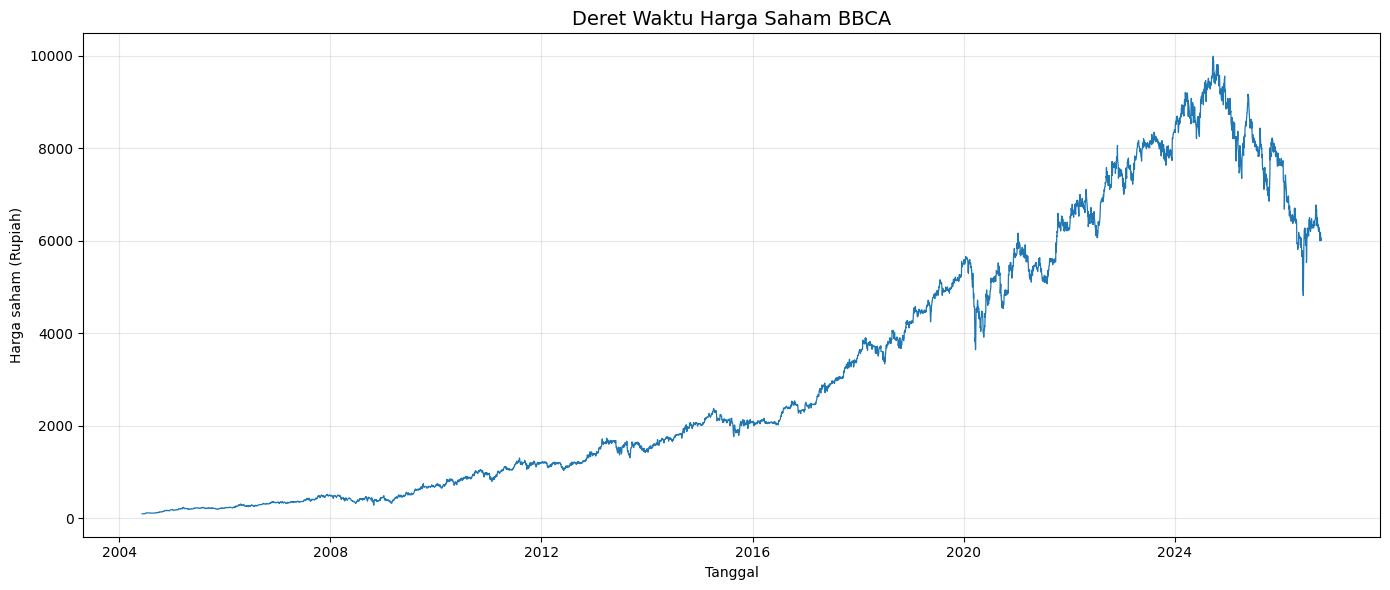

In [ ]:

# ============================================================
# TAHAP 1D. PLOT DERET WAKTU
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    harga.index,
    harga.values,
    linewidth=0.9
)

plt.title(
    "Deret Waktu Harga Saham BBCA",
    fontsize=14
)
plt.xlabel("Tanggal")
plt.ylabel("Harga saham (Rupiah)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


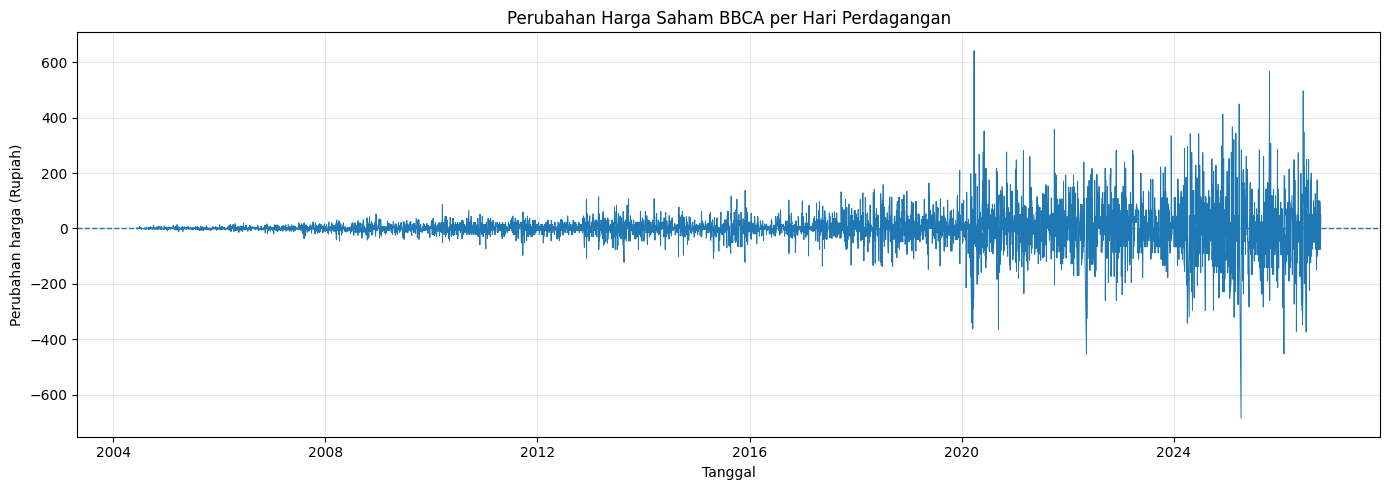


Statistik perubahan harga:
count    5504.0000
mean        1.0821
std        65.4681
min      -685.1768
25%       -14.6438
50%         0.0000
75%        15.3518
max       641.3938
Name: BBCA, dtype: float64


In [ ]:

# ============================================================
# TAHAP 1E. PERUBAHAN HARGA HARIAN
# ============================================================

perubahan_harga = harga.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(
    perubahan_harga.index,
    perubahan_harga.values,
    linewidth=0.7
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Perubahan Harga Saham BBCA per Hari Perdagangan")
plt.xlabel("Tanggal")
plt.ylabel("Perubahan harga (Rupiah)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStatistik perubahan harga:")
print(perubahan_harga.describe().round(4))


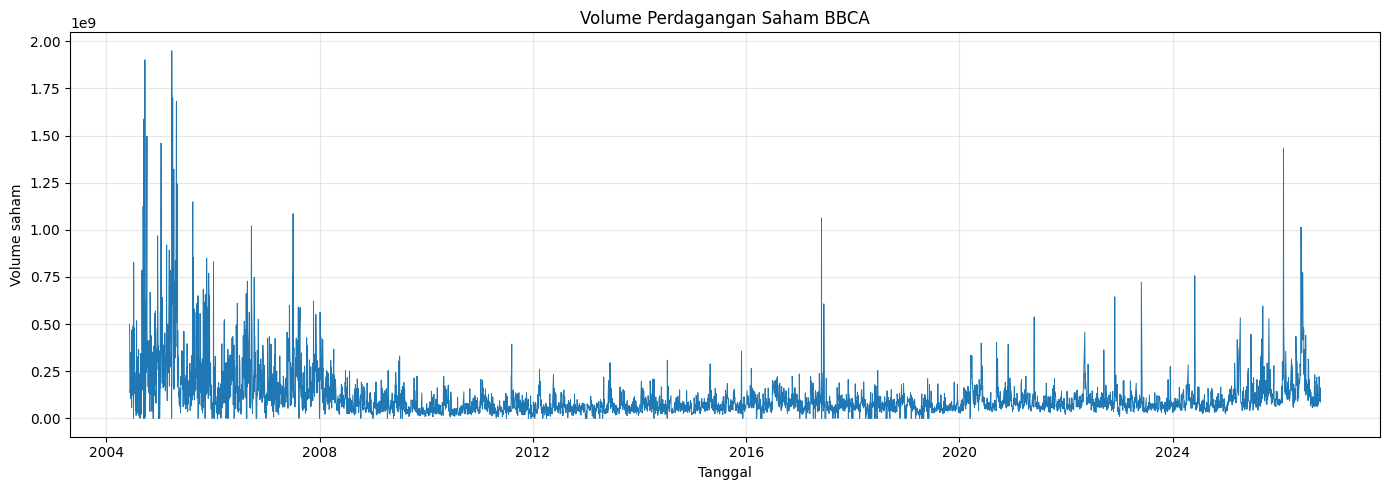

In [ ]:

# ============================================================
# TAHAP 1F. EKSPLORASI VOLUME PERDAGANGAN
# ============================================================

if "Volume" in df.columns:

    volume = df["Volume"].dropna()

    plt.figure(figsize=(14, 5))
    plt.plot(
        volume.index,
        volume.values,
        linewidth=0.7
    )

    plt.title("Volume Perdagangan Saham BBCA")
    plt.xlabel("Tanggal")
    plt.ylabel("Volume saham")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("Kolom Volume tidak tersedia.")


HASIL PEMBAGIAN DATA SAHAM BBCA
Total observasi : 5505
Training        : 4404 (80.00%)
Testing         : 1101 (20.00%)

Periode Training
Tanggal awal : 2004-06-08 00:00:00
Tanggal akhir: 2022-03-01 00:00:00

Periode Testing
Tanggal awal : 2022-03-02 00:00:00
Tanggal akhir: 2026-10-09 00:00:00


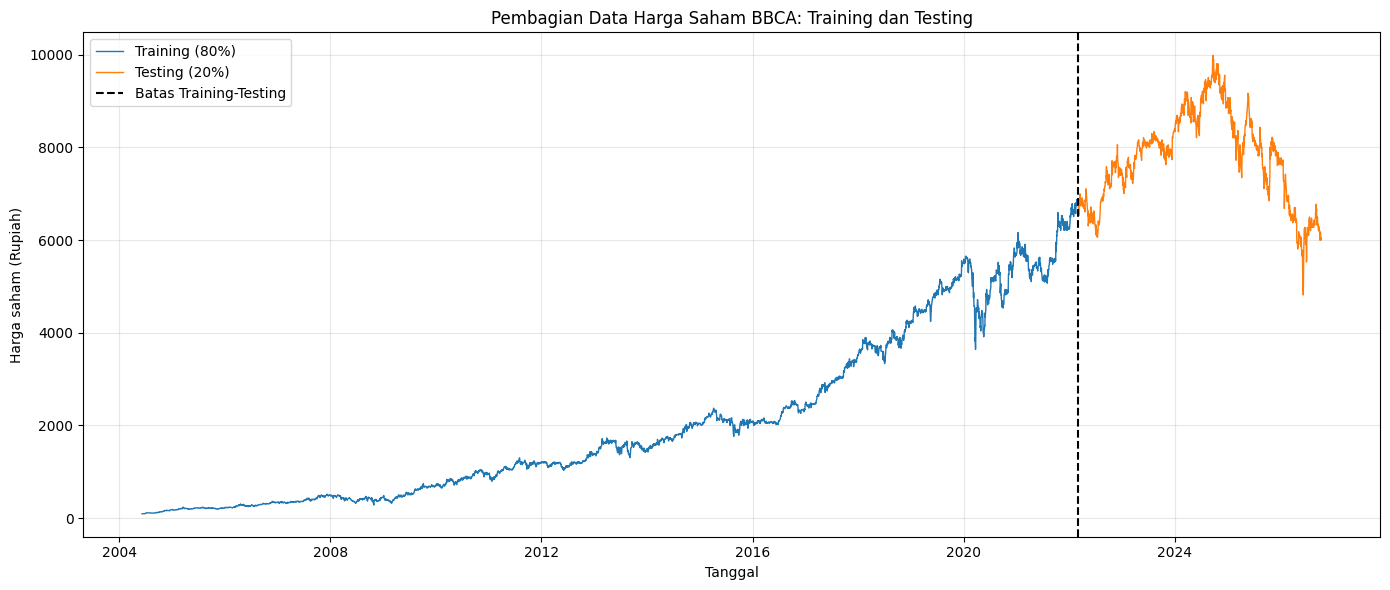

In [ ]:

# ============================================================
# TAHAP 2. PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Memastikan data tersusun berdasarkan waktu
harga = harga.sort_index()

# Proporsi pembagian data
train_size = 0.80

# Menentukan titik pemisah
split_idx = int(len(harga) * train_size)

# Membagi data secara kronologis
train = harga.iloc[:split_idx].copy()
test = harga.iloc[split_idx:].copy()

# ============================================================
# INFORMASI HASIL PEMBAGIAN DATA
# ============================================================

print("=" * 60)
print("HASIL PEMBAGIAN DATA SAHAM BBCA")
print("=" * 60)

print(f"Total observasi : {len(harga)}")
print(f"Training        : {len(train)} ({len(train)/len(harga)*100:.2f}%)")
print(f"Testing         : {len(test)} ({len(test)/len(harga)*100:.2f}%)")

print("\nPeriode Training")
print("Tanggal awal :", train.index.min())
print("Tanggal akhir:", train.index.max())

print("\nPeriode Testing")
print("Tanggal awal :", test.index.min())
print("Tanggal akhir:", test.index.max())

# ============================================================
# VISUALISASI TRAINING DAN TESTING
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training (80%)",
    linewidth=1
)

plt.plot(
    test.index,
    test,
    label="Testing (20%)",
    linewidth=1
)

plt.axvline(
    x=test.index[0],
    color="black",
    linestyle="--",
    label="Batas Training-Testing"
)

plt.title("Pembagian Data Harga Saham BBCA: Training dan Testing")
plt.xlabel("Tanggal")
plt.ylabel("Harga saham (Rupiah)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Lambda Box-Cox: 0.1761

Statistik training setelah Box-Cox:
count    4404.0000
mean       14.5894
std         3.8034
min         6.9664
25%        10.9925
50%        14.8918
75%        17.9390
max        21.2396
Name: BBCA_BoxCox, dtype: float64


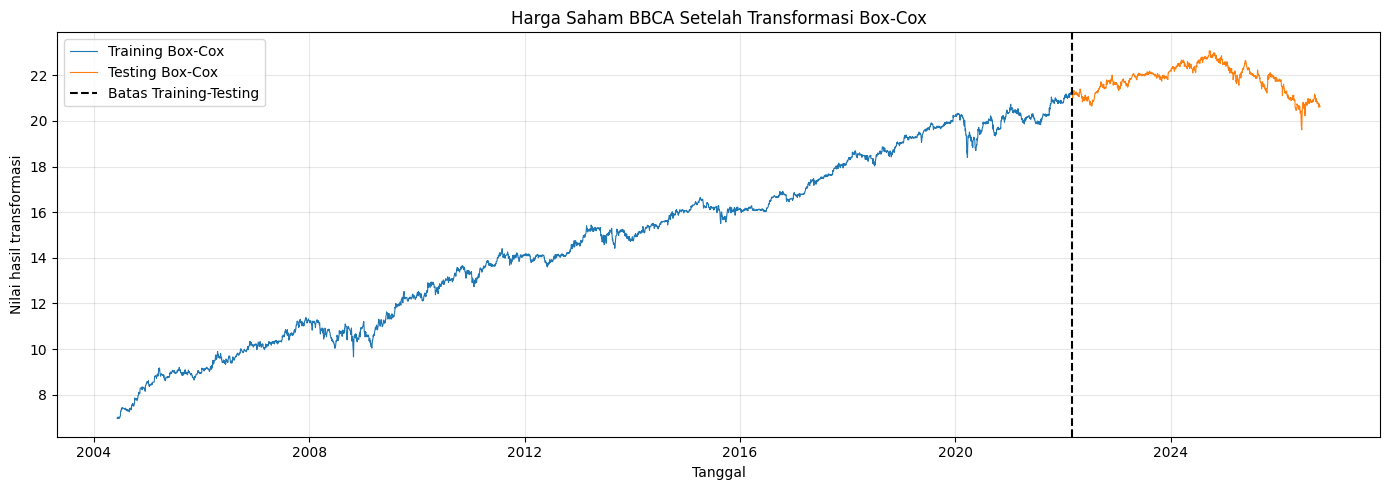

In [ ]:

# ============================================================
# TAHAP 2A. TRANSFORMASI BOX-COX
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from scipy.special import boxcox as boxcox_transform

# Pastikan seluruh observasi bernilai positif
assert (train > 0).all(), "Training harus bernilai positif."
assert (test > 0).all(), "Testing harus bernilai positif."

# Estimasi lambda hanya menggunakan data training
train_boxcox_values, lambda_boxcox = boxcox(
    train.to_numpy()
)

# Transformasi testing dengan lambda training
test_boxcox_values = boxcox_transform(
    test.to_numpy(),
    lambda_boxcox
)

# Membentuk Series agar indeks tanggal tetap terjaga
train_boxcox = pd.Series(
    train_boxcox_values,
    index=train.index,
    name="BBCA_BoxCox"
)

test_boxcox = pd.Series(
    test_boxcox_values,
    index=test.index,
    name="BBCA_BoxCox"
)

print("Lambda Box-Cox:", round(lambda_boxcox, 4))

print("\nStatistik training setelah Box-Cox:")
print(train_boxcox.describe().round(4))

# Plot hasil transformasi
plt.figure(figsize=(14, 5))

plt.plot(
    train_boxcox.index,
    train_boxcox,
    label="Training Box-Cox",
    linewidth=0.8
)

plt.plot(
    test_boxcox.index,
    test_boxcox,
    label="Testing Box-Cox",
    linewidth=0.8
)

plt.axvline(
    x=test_boxcox.index[0],
    color="black",
    linestyle="--",
    label="Batas Training-Testing"
)

plt.title("Harga Saham BBCA Setelah Transformasi Box-Cox")
plt.xlabel("Tanggal")
plt.ylabel("Nilai hasil transformasi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# TAHAP 2B. UJI STASIONERITAS ADF DAN KPSS
# ============================================================

from statsmodels.tsa.stattools import adfuller, kpss
import warnings

def uji_stasioneritas(data, nama):
    data = pd.Series(data).dropna()

    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    # Uji ADF
    hasil_adf = adfuller(
        data,
        regression="c",
        autolag="AIC"
    )

    print("\nUJI ADF")
    print("ADF Statistic :", round(hasil_adf[0], 6))
    print("p-value       :", round(hasil_adf[1], 6))
    print("Lag terpilih  :", hasil_adf[2])
    print("Observasi     :", hasil_adf[3])

    if hasil_adf[1] < 0.05:
        print("Kesimpulan ADF: Tolak H0; bukti mendukung stasioneritas.")
    else:
        print("Kesimpulan ADF: Gagal menolak H0; unit root belum dapat disingkirkan.")

    # Uji KPSS
    with warnings.catch_warnings():
        warnings.simplefilter("always")
        hasil_kpss = kpss(
            data,
            regression="c",
            nlags="auto"
        )

    print("\nUJI KPSS")
    print("KPSS Statistic:", round(hasil_kpss[0], 6))
    print("p-value       :", round(hasil_kpss[1], 6))
    print("Lag terpilih  :", hasil_kpss[2])

    if hasil_kpss[1] < 0.05:
        print("Kesimpulan KPSS: Tolak H0; bukti mendukung ketidakstasioneran.")
    else:
        print("Kesimpulan KPSS: Gagal menolak H0; stasioneritas belum ditolak.")

# Pengujian hanya pada data training
uji_stasioneritas(
    train_boxcox,
    "TRAINING SETELAH TRANSFORMASI BOX-COX"
)



TRAINING SETELAH TRANSFORMASI BOX-COX

UJI ADF
ADF Statistic : -0.997073
p-value       : 0.75433
Lag terpilih  : 7
Observasi     : 4396
Kesimpulan ADF: Gagal menolak H0; unit root belum dapat disingkirkan.

UJI KPSS
KPSS Statistic: 10.719048
p-value       : 0.01
Lag terpilih  : 40
Kesimpulan KPSS: Tolak H0; bukti mendukung ketidakstasioneran.


/tmp/ipykernel_594/2992473538.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil_adf = adfuller(
/tmp/ipykernel_594/2992473538.py:36: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  hasil_kpss = kpss(
/tmp/ipykernel_594/2992473538.py:36: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or 

Jumlah observasi training setelah differencing 1: 4403


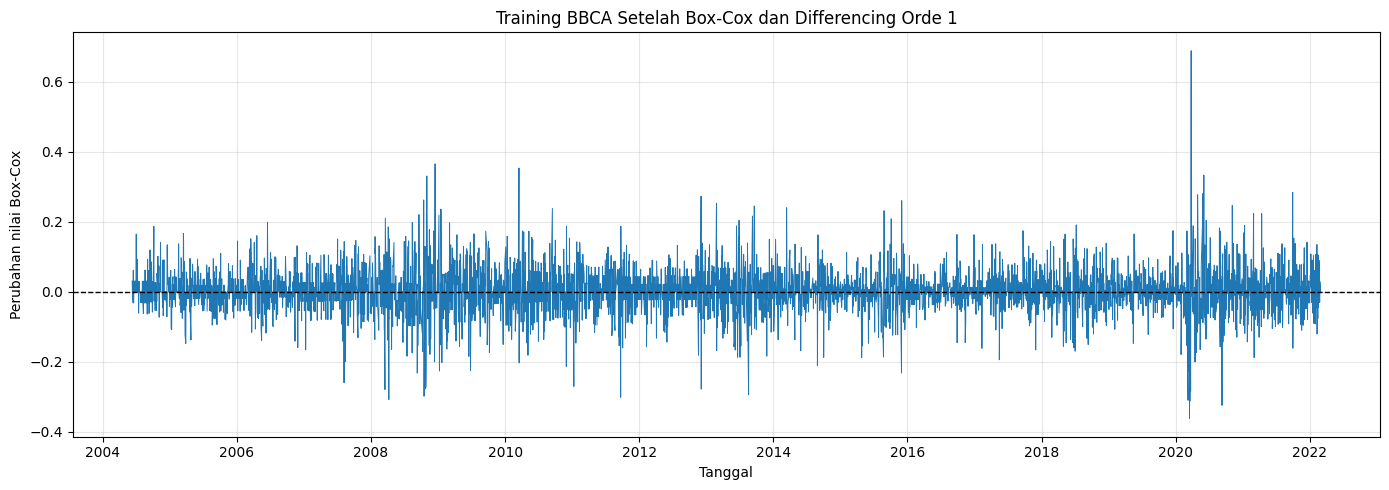


UJI ADF - DIFFERENCING ORDE 1
ADF Statistic : -28.260497
p-value       : 0.0
Lag terpilih  : 6
Kesimpulan: Tolak H0; data mendukung stasioneritas.

UJI KPSS - DIFFERENCING ORDE 1
KPSS Statistic: 0.04469
p-value       : 0.1
Lag terpilih  : 30
Kesimpulan: Gagal menolak H0; stasioneritas level belum ditolak.


/tmp/ipykernel_594/2840827775.py:30: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil_adf_d1 = adfuller(
/tmp/ipykernel_594/2840827775.py:52: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  hasil_kpss_d1 = kpss(
/tmp/ipykernel_594/2840827775.py:52: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch no

In [ ]:

# ============================================================
# TAHAP 2C. DIFFERENCING ORDE 1
# ============================================================

from statsmodels.tsa.stattools import adfuller, kpss
import matplotlib.pyplot as plt
import warnings

# Differencing pertama pada training hasil Box-Cox
train_diff1 = train_boxcox.diff().dropna()

print("Jumlah observasi training setelah differencing 1:",
      len(train_diff1))

# Visualisasi
plt.figure(figsize=(14, 5))
plt.plot(train_diff1.index, train_diff1, linewidth=0.7)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Training BBCA Setelah Box-Cox dan Differencing Orde 1")
plt.xlabel("Tanggal")
plt.ylabel("Perubahan nilai Box-Cox")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# UJI ADF
# ============================================================

hasil_adf_d1 = adfuller(
    train_diff1,
    regression="c",
    autolag="AIC"
)

print("\nUJI ADF - DIFFERENCING ORDE 1")
print("ADF Statistic :", round(hasil_adf_d1[0], 6))
print("p-value       :", round(hasil_adf_d1[1], 6))
print("Lag terpilih  :", hasil_adf_d1[2])

if hasil_adf_d1[1] < 0.05:
    print("Kesimpulan: Tolak H0; data mendukung stasioneritas.")
else:
    print("Kesimpulan: Gagal menolak H0; unit root belum tersingkir.")

# ============================================================
# UJI KPSS
# ============================================================

with warnings.catch_warnings():
    warnings.simplefilter("always")
    hasil_kpss_d1 = kpss(
        train_diff1,
        regression="c",
        nlags="auto"
    )

print("\nUJI KPSS - DIFFERENCING ORDE 1")
print("KPSS Statistic:", round(hasil_kpss_d1[0], 6))
print("p-value       :", round(hasil_kpss_d1[1], 6))
print("Lag terpilih  :", hasil_kpss_d1[2])

if hasil_kpss_d1[1] < 0.05:
    print("Kesimpulan: Tolak H0; data mendukung ketidakstasioneran.")
else:
    print("Kesimpulan: Gagal menolak H0; stasioneritas level belum ditolak.")


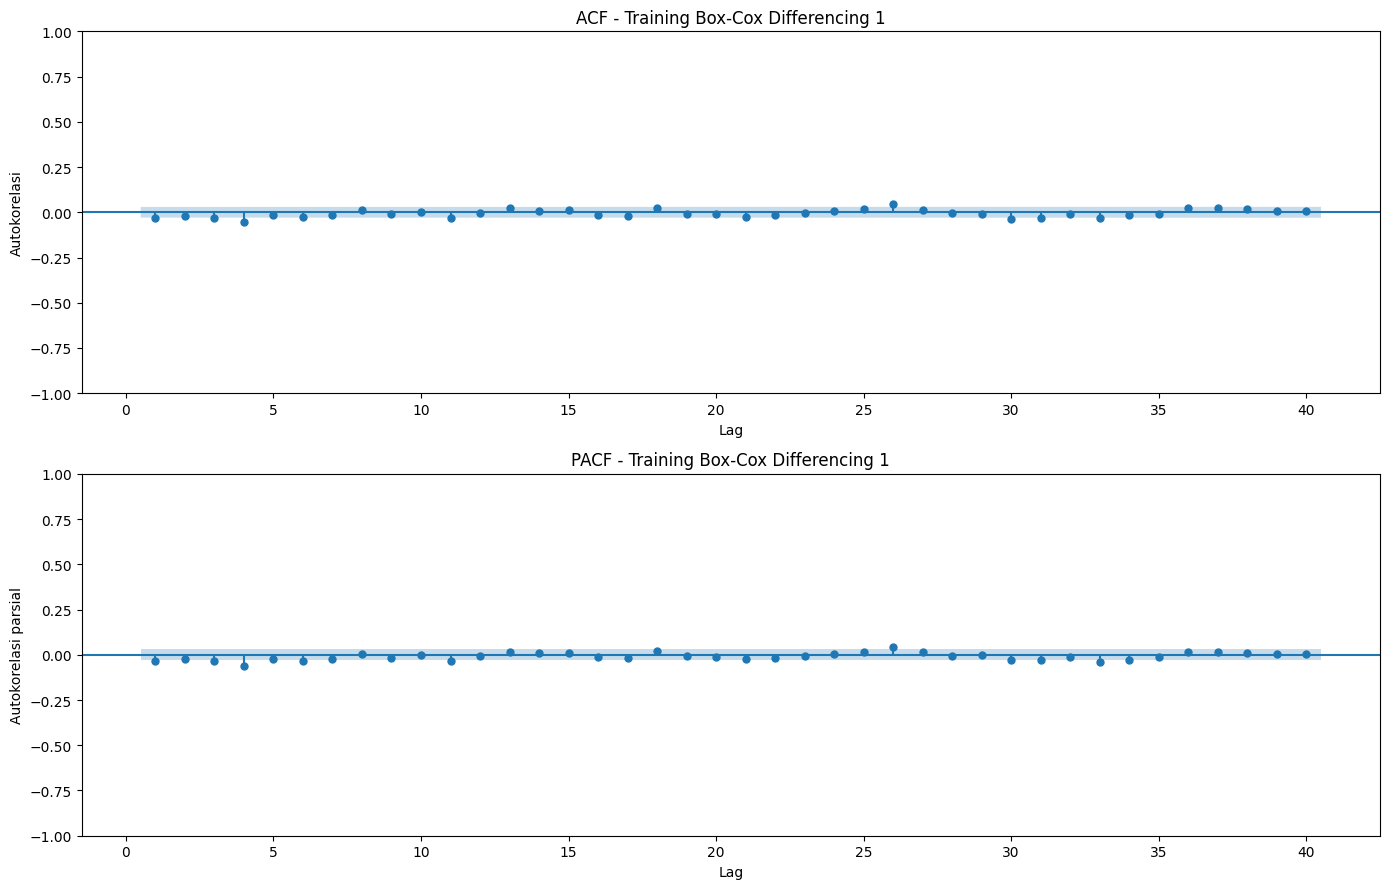

In [ ]:

# ============================================================
# TAHAP 3. IDENTIFIKASI ACF DAN PACF
# ============================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Menggunakan data training yang sudah stasioner
data_identifikasi = train_diff1.dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ACF
plot_acf(
    data_identifikasi,
    lags=40,
    zero=False,
    ax=axes[0]
)
axes[0].set_title("ACF - Training Box-Cox Differencing 1")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autokorelasi")

# PACF
plot_pacf(
    data_identifikasi,
    lags=40,
    method="ywm",
    zero=False,
    ax=axes[1]
)
axes[1].set_title("PACF - Training Box-Cox Differencing 1")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Autokorelasi parsial")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# TAHAP 4A. ESTIMASI DAN PEMILIHAN MODEL ARIMA
# ============================================================

import warnings
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# Kandidat model berdasarkan pola ACF dan PACF
kandidat = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

hasil_model = []
model_terestimasi = {}

for order in kandidat:
    try:
        model = ARIMA(
            train_boxcox,
            order=order,
            trend="n"
        ).fit()

        model_terestimasi[order] = model

        hasil_model.append({
            "Model": f"ARIMA{order}",
            "p": order[0],
            "d": order[1],
            "q": order[2],
            "AIC": model.aic,
            "BIC": model.bic
        })

    except Exception as e:
        print(f"Model ARIMA{order} gagal: {e}")

# Tabel perbandingan
tabel_model = pd.DataFrame(hasil_model)
tabel_model = tabel_model.sort_values("AIC").reset_index(drop=True)

print("PERBANDINGAN KANDIDAT ARIMA")
print(tabel_model.round(3).to_string(index=False))

# Model terbaik berdasarkan AIC
model_terbaik_order = tuple(
    int(tabel_model.loc[0, kolom])
    for kolom in ["p", "d", "q"]
)

model_terbaik = model_terestimasi[model_terbaik_order]

print("\nModel dengan AIC terkecil:", model_terbaik_order)
print("AIC:", round(model_terbaik.aic, 3))
print("BIC:", round(model_terbaik.bic, 3))


PERBANDINGAN KANDIDAT ARIMA
         Model  p  d  q        AIC        BIC
ARIMA(2, 1, 2)  2  1  2 -11553.585 -11521.635
ARIMA(1, 1, 2)  1  1  2 -11552.148 -11526.588
ARIMA(1, 1, 1)  1  1  1 -11551.404 -11532.234
ARIMA(0, 1, 2)  0  1  2 -11536.830 -11517.659
ARIMA(0, 1, 1)  0  1  1 -11536.817 -11524.037
ARIMA(1, 1, 0)  1  1  0 -11536.643 -11523.863
ARIMA(2, 1, 0)  2  1  0 -11536.211 -11517.041
ARIMA(0, 1, 0)  0  1  0 -11534.340 -11527.950
ARIMA(2, 1, 1)  2  1  1 -11534.302 -11508.742

Model dengan AIC terkecil: (2, 1, 2)
AIC: -11553.585
BIC: -11521.635


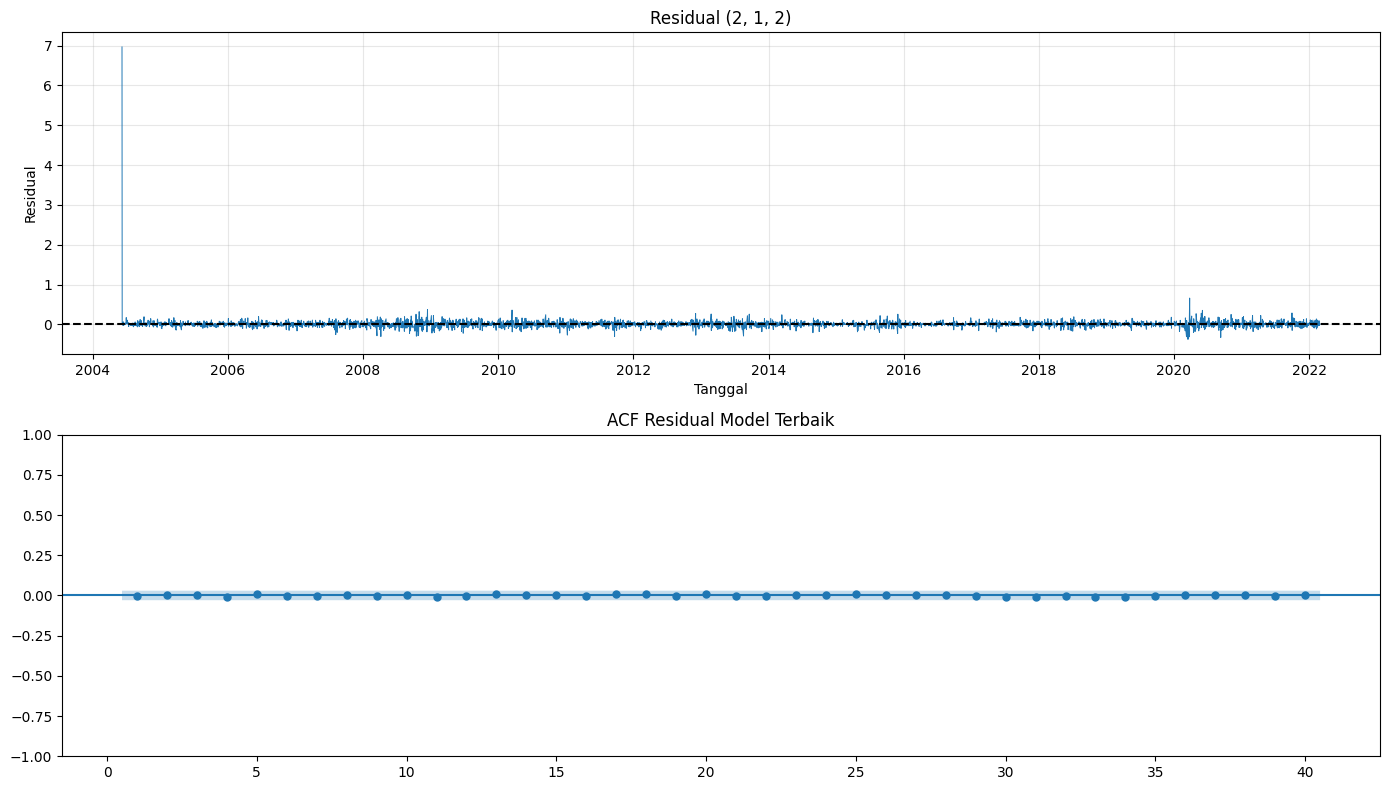


UJI LJUNG-BOX
     lb_stat  lb_pvalue
10  1.186904   0.977527
20  2.997857   0.999831


In [ ]:

# ============================================================
# TAHAP 4B. DIAGNOSTIK RESIDUAL
# ============================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

residual = model_terbaik.resid.dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residual.index, residual, linewidth=0.7)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title(f"Residual {model_terbaik_order}")
axes[0].set_xlabel("Tanggal")
axes[0].set_ylabel("Residual")
axes[0].grid(True, alpha=0.3)

plot_acf(
    residual,
    lags=40,
    zero=False,
    ax=axes[1]
)
axes[1].set_title("ACF Residual Model Terbaik")

plt.tight_layout()
plt.show()

# Uji Ljung-Box
hasil_lb = acorr_ljungbox(
    residual,
    lags=[10, 20],
    return_df=True,
    model_df=model_terbaik_order[0] + model_terbaik_order[2]
)

print("\nUJI LJUNG-BOX")
print(hasil_lb)


Training index: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Tanggal training: 2004-06-08 00:00:00 sampai 2022-03-01 00:00:00
Tanggal testing: 2022-03-02 00:00:00 sampai 2026-10-09 00:00:00

HASIL EVALUASI ARIMA(2,1,2)
MAE  : 1123.8706
RMSE : 1340.6499
MAPE : 13.7312%


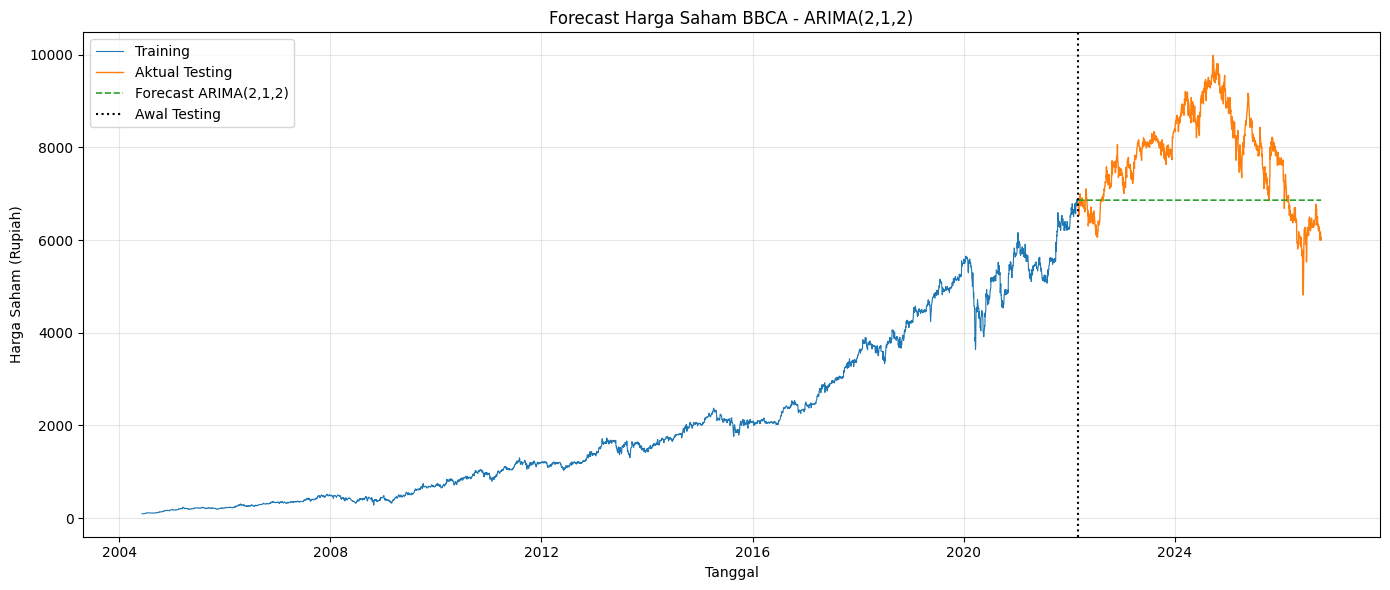

In [ ]:

# ============================================================
# PERBAIKAN FORECASTING ARIMA(2,1,2)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import inv_boxcox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

# ------------------------------------------------------------
# 1. Memastikan indeks tanggal valid
# ------------------------------------------------------------

train_boxcox = train_boxcox.copy()
test_boxcox = test_boxcox.copy()

train_boxcox.index = pd.DatetimeIndex(train_boxcox.index)
test_boxcox.index = pd.DatetimeIndex(test_boxcox.index)

train_boxcox = train_boxcox.sort_index()
test_boxcox = test_boxcox.sort_index()

print("Training index:", type(train_boxcox.index))
print("Tanggal training:", train_boxcox.index.min(),
      "sampai", train_boxcox.index.max())
print("Tanggal testing:", test_boxcox.index.min(),
      "sampai", test_boxcox.index.max())

# ------------------------------------------------------------
# 2. Fit ulang model ARIMA pada training
# ------------------------------------------------------------

# Gunakan indeks numerik berurutan untuk menghindari
# masalah frekuensi indeks tanggal perdagangan.
y_train = train_boxcox.to_numpy(dtype=float)

model_final = ARIMA(
    y_train,
    order=(2, 1, 2),
    trend="n"
).fit()

# ------------------------------------------------------------
# 3. Forecast sepanjang periode testing
# ------------------------------------------------------------

horizon = len(test)

forecast_result = model_final.get_forecast(
    steps=horizon
)

forecast_boxcox = np.asarray(
    forecast_result.predicted_mean
)

# Mengembalikan hasil transformasi ke skala harga
if abs(lambda_boxcox) < 1e-8:
    forecast_original = np.exp(forecast_boxcox)
else:
    forecast_original = inv_boxcox(
        forecast_boxcox,
        lambda_boxcox
    )

forecast = pd.Series(
    forecast_original,
    index=test.index,
    name="Forecast"
)

# ------------------------------------------------------------
# 4. Evaluasi
# ------------------------------------------------------------

actual = test.astype(float)

mae = mean_absolute_error(actual, forecast)
rmse = np.sqrt(mean_squared_error(actual, forecast))
mape = np.mean(
    np.abs((actual.to_numpy() - forecast.to_numpy())
           / actual.to_numpy())
) * 100

print("\nHASIL EVALUASI ARIMA(2,1,2)")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.4f}%")

# ------------------------------------------------------------
# 5. Plot aktual vs forecast
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    train.index, train,
    label="Training", linewidth=0.8
)

plt.plot(
    actual.index, actual,
    label="Aktual Testing", linewidth=1
)

plt.plot(
    forecast.index, forecast,
    label="Forecast ARIMA(2,1,2)",
    linestyle="--", linewidth=1.2
)

plt.axvline(
    x=test.index[0],
    color="black", linestyle=":",
    label="Awal Testing"
)

plt.title("Forecast Harga Saham BBCA - ARIMA(2,1,2)")
plt.xlabel("Tanggal")
plt.ylabel("Harga Saham (Rupiah)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# TAHAP 6. MEMBANDINGKAN MODEL ARIMA DAN NAIVE FORECAST
# ============================================================

import numpy as np
import pandas as pd

from scipy.special import inv_boxcox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

# Harga aktual pada periode testing
actual = test.astype(float)

# Fungsi mengembalikan forecast Box-Cox ke skala harga
def inverse_forecast(values, lam):
    values = np.asarray(values)

    if abs(lam) < 1e-8:
        return np.exp(values)

    return inv_boxcox(values, lam)

# Training Box-Cox dalam bentuk array
y_train = train_boxcox.to_numpy(dtype=float)

hasil_perbandingan = []
ramalan_model = {}

# Kandidat model yang dibandingkan
for order in [(2, 1, 2), (1, 1, 1)]:
    fitted = ARIMA(
        y_train,
        order=order,
        trend="n"
    ).fit()

    pred_boxcox = fitted.get_forecast(
        steps=len(test)
    ).predicted_mean

    pred = inverse_forecast(
        pred_boxcox,
        lambda_boxcox
    )

    pred = pd.Series(
        pred,
        index=test.index
    )

    ramalan_model[str(order)] = pred

    hasil_perbandingan.append({
        "Model": f"ARIMA{order}",
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": np.mean(
            np.abs((actual.to_numpy() - pred.to_numpy())
                   / actual.to_numpy())
        ) * 100
    })

# Naive forecast: seluruh ramalan sama dengan
# observasi terakhir training pada skala harga asli
naive_pred = pd.Series(
    float(train.iloc[-1]),
    index=test.index
)

ramalan_model["Naive"] = naive_pred

hasil_perbandingan.append({
    "Model": "Naive Forecast",
    "MAE": mean_absolute_error(actual, naive_pred),
    "RMSE": np.sqrt(mean_squared_error(actual, naive_pred)),
    "MAPE (%)": np.mean(
        np.abs((actual.to_numpy() - naive_pred.to_numpy())
               / actual.to_numpy())
    ) * 100
})

tabel_perbandingan = pd.DataFrame(
    hasil_perbandingan
).sort_values("RMSE").reset_index(drop=True)

print(tabel_perbandingan.round(4).to_string(index=False))


         Model       MAE      RMSE  MAPE (%)
Naive Forecast 1118.8406 1334.4961   13.6763
ARIMA(2, 1, 2) 1123.8706 1340.6499   13.7312
ARIMA(1, 1, 1) 1139.3325 1359.2320   13.9016



Skenario 1 (90:10)
Training: 4954 observasi
Periode: 2004-06-08 00:00:00 sampai 2024-06-21 00:00:00
Testing : 551 observasi
Periode: 2024-06-24 00:00:00 sampai 2026-10-09 00:00:00

Skenario 2 (85:15)
Training: 4679 observasi
Periode: 2004-06-08 00:00:00 sampai 2023-04-12 00:00:00
Testing : 826 observasi
Periode: 2023-04-13 00:00:00 sampai 2026-10-09 00:00:00

Skenario 3 (80:20)
Training: 4404 observasi
Periode: 2004-06-08 00:00:00 sampai 2022-03-01 00:00:00
Testing : 1101 observasi
Periode: 2022-03-02 00:00:00 sampai 2026-10-09 00:00:00

Skenario 4 (70:30)
Training: 3853 observasi
Periode: 2004-06-08 00:00:00 sampai 2019-11-26 00:00:00
Testing : 1652 observasi
Periode: 2019-11-27 00:00:00 sampai 2026-10-09 00:00:00


TABEL PEMBAGIAN DATA
          Skenario  Proporsi Training (%)  Jumlah Training  Jumlah Testing Awal Training Akhir Training Awal Testing Akhir Testing
Skenario 1 (90:10)                   90.0             4954             551    2004-06-08     2024-06-21   2024-06-24    

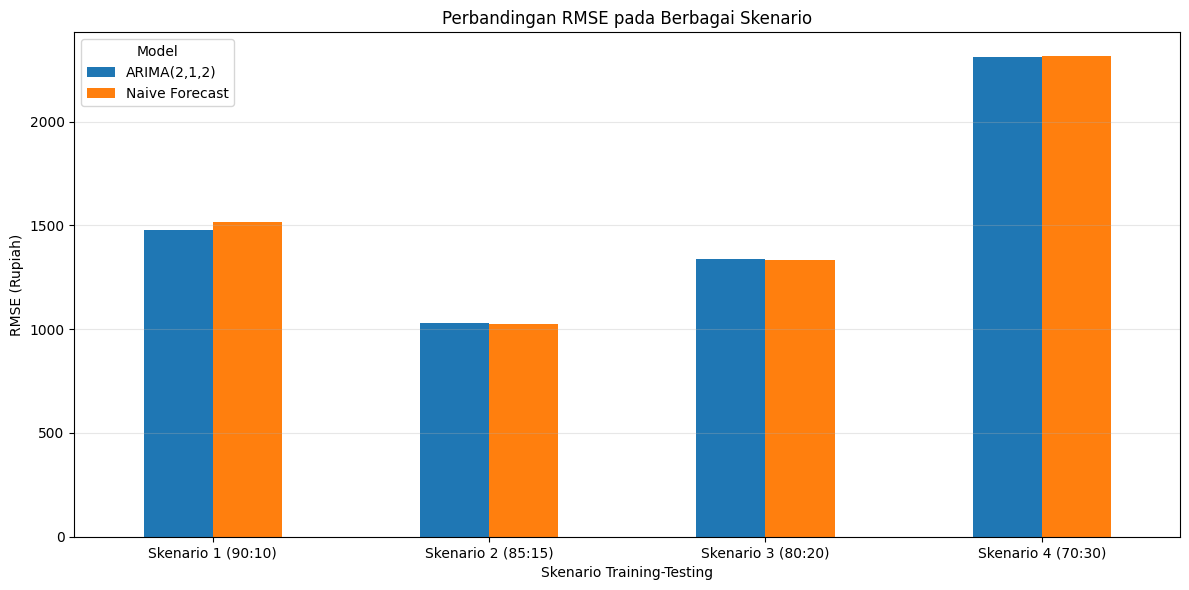

In [ ]:

# ============================================================
# ANALISIS BEBERAPA SKENARIO TRAINING-TESTING BBCA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from scipy.special import boxcox as boxcox_transform
from scipy.special import inv_boxcox

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------

# Menggunakan harga dari tahap eksplorasi sebelumnya
data = harga.dropna().astype(float).sort_index()

# Memastikan tidak ada duplikasi tanggal
data = data[~data.index.duplicated(keep="first")]

assert len(data) > 0, "Data harga kosong."
assert (data > 0).all(), "Box-Cox membutuhkan data positif."

# Skenario pembagian data
skenario = {
    "Skenario 1 (90:10)": 0.90,
    "Skenario 2 (85:15)": 0.85,
    "Skenario 3 (80:20)": 0.80,
    "Skenario 4 (70:30)": 0.70
}

# Menyimpan hasil dan ramalan
hasil_evaluasi = []
hasil_ramalan = {}
informasi_split = []

# ------------------------------------------------------------
# 2. LOOP SELURUH SKENARIO
# ------------------------------------------------------------

for nama, proporsi_train in skenario.items():

    print("\n" + "=" * 65)
    print(nama)
    print("=" * 65)

    # Pembagian kronologis
    split_idx = int(len(data) * proporsi_train)

    train_s = data.iloc[:split_idx].copy()
    test_s = data.iloc[split_idx:].copy()

    informasi_split.append({
        "Skenario": nama,
        "Proporsi Training (%)": proporsi_train * 100,
        "Jumlah Training": len(train_s),
        "Jumlah Testing": len(test_s),
        "Awal Training": train_s.index.min(),
        "Akhir Training": train_s.index.max(),
        "Awal Testing": test_s.index.min(),
        "Akhir Testing": test_s.index.max()
    })

    print("Training:", len(train_s), "observasi")
    print("Periode:", train_s.index.min(), "sampai",
          train_s.index.max())
    print("Testing :", len(test_s), "observasi")
    print("Periode:", test_s.index.min(), "sampai",
          test_s.index.max())

    # --------------------------------------------------------
    # 3. BOX-COX: ESTIMASI LAMBDA DARI TRAINING SAJA
    # --------------------------------------------------------

    train_bc_values, lambda_s = boxcox(train_s.to_numpy())

    test_bc_values = boxcox_transform(
        test_s.to_numpy(),
        lambda_s
    )

    train_bc = pd.Series(
        train_bc_values,
        index=train_s.index
    )

    # --------------------------------------------------------
    # 4. FIT ARIMA(2,1,2) PADA TRAINING
    # --------------------------------------------------------

    model_s = ARIMA(
        train_bc.to_numpy(),
        order=(2, 1, 2),
        trend="n"
    ).fit()

    forecast_bc = np.asarray(
        model_s.get_forecast(
            steps=len(test_s)
        ).predicted_mean
    )

    # Mengembalikan ramalan ke skala harga asli
    if abs(lambda_s) < 1e-8:
        forecast_arima = np.exp(forecast_bc)
    else:
        forecast_arima = inv_boxcox(
            forecast_bc,
            lambda_s
        )

    forecast_arima = pd.Series(
        forecast_arima,
        index=test_s.index,
        name="ARIMA(2,1,2)"
    )

    # --------------------------------------------------------
    # 5. NAIVE FORECAST
    # --------------------------------------------------------

    # Harga terakhir training untuk semua titik testing
    forecast_naive = pd.Series(
        float(train_s.iloc[-1]),
        index=test_s.index,
        name="Naive"
    )

    hasil_ramalan[nama] = pd.DataFrame({
        "Aktual": test_s,
        "ARIMA(2,1,2)": forecast_arima,
        "Naive Forecast": forecast_naive
    })

    # --------------------------------------------------------
    # 6. EVALUASI KINERJA
    # --------------------------------------------------------

    for nama_model, prediksi in [
        ("ARIMA(2,1,2)", forecast_arima),
        ("Naive Forecast", forecast_naive)
    ]:

        aktual = test_s.to_numpy()
        pred = prediksi.to_numpy()

        mae = mean_absolute_error(aktual, pred)
        rmse = np.sqrt(mean_squared_error(aktual, pred))
        mape = np.mean(
            np.abs((aktual - pred) / aktual)
        ) * 100

        hasil_evaluasi.append({
            "Skenario": nama,
            "Proporsi Training (%)": proporsi_train * 100,
            "Model": nama_model,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape,
            "Lambda Box-Cox": lambda_s,
            "AIC": model_s.aic if nama_model == "ARIMA(2,1,2)"
                   else np.nan
        })

# ------------------------------------------------------------
# 7. TABEL PERIODE TRAINING-TESTING
# ------------------------------------------------------------

tabel_split = pd.DataFrame(informasi_split)

print("\n\nTABEL PEMBAGIAN DATA")
print(tabel_split.to_string(index=False))

# ------------------------------------------------------------
# 8. TABEL EVALUASI SELURUH SKENARIO
# ------------------------------------------------------------

tabel_evaluasi = pd.DataFrame(hasil_evaluasi)

print("\n\nTABEL PERBANDINGAN KINERJA")
print(
    tabel_evaluasi.sort_values(
        ["Skenario", "RMSE"]
    ).round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 9. VISUALISASI RMSE
# ------------------------------------------------------------

tabel_plot = tabel_evaluasi.pivot(
    index="Skenario",
    columns="Model",
    values="RMSE"
)

urutan_skenario = list(skenario.keys())
tabel_plot = tabel_plot.reindex(urutan_skenario)

ax = tabel_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Perbandingan RMSE pada Berbagai Skenario")
ax.set_xlabel("Skenario Training-Testing")
ax.set_ylabel("RMSE (Rupiah)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
